# Lab 5 · Instance segmentation with Mask R-CNN: people in a crowd

**Course lab:** `CV-Week3-Lecture5.ipynb` (in `course-files/labs/`)
**Theory partner:** [notes/05_segmentation_fcn_unet_mask_rcnn.md](../notes/05_segmentation_fcn_unet_mask_rcnn.md) (Mask R-CNN section) and [notebooks/05_segmentation_fcn_unet_mask_rcnn.ipynb](../notebooks/05_segmentation_fcn_unet_mask_rcnn.ipynb). The COCO loader is explained in detail in [Lab 3](lab3_object_detection_faster_rcnn_yolo.ipynb).

| Course cell | What it does | What you will see here |
|---|---|---|
| Setup: COCO loader (for segmentation) | `CocoDetection` with polygon annotations | real COCO images with their **instance masks** decoded from polygons |
| Exercise: segment multiple objects | pretrained Mask R-CNN on a batch | the output format (`boxes`, `labels`, `scores`, `masks`), coloured instance masks, and a mask precision/recall measurement on 128 labelled images |
| Mini project: people in crowd images | keep the `person` masks | every person in a distinct colour, a **people count**, what the course's 224×224 resize does to that count, and a score-threshold sweep |

**What you will learn:** what an instance mask is, how Mask R-CNN's soft masks become binary masks, why a score threshold matters, how to count objects reliably, and how to fail gracefully when nothing is found.

**Run time:** about 8–10 minutes on the shared CPU this was built on (evaluating masks on all 128 images took 361 s); an idle laptop will be faster. On Colab with a GPU: under a minute.

## 0 · Theory in 60 seconds

- **Instance segmentation** = detection + a pixel mask **per object**. Two people standing together give **two** masks (semantic segmentation would give one "person" blob).
- **Mask R-CNN** = **Faster R-CNN + a third head**. For each proposed region (RoI) it predicts a class, a refined box **and** a small 28×28 mask. **RoI Align** samples the feature map at exact (non-rounded) positions so the small mask lines up with the object. The mask is then resized and pasted into the box.
- **torchvision's output** (one dict per image): `boxes [N,4]`, `labels [N]` (COCO ids, **1 = person**), `scores [N]`, and `masks [N,1,H,W]`: **soft probabilities 0–1 at the full image size**, so you threshold them with **`> 0.5`**.
- **YOLOv8-seg** (the fallback here) is a one-stage instance segmenter: it predicts a set of shared "prototype" masks for the whole image plus, per detected object, coefficients that mix the prototypes into that object's mask (the YOLACT idea). Same kind of output, much faster.

> **Two routes for the downloads.** The course uses torchvision's `maskrcnn_resnet50_fpn` (weights from `download.pytorch.org`) and full COCO (`images.cocodataset.org`). With normal internet this notebook uses both. The machine that ran it **could not reach those servers**, so each cell tries the course's route first and otherwise falls back to **Ultralytics COCO128-seg** (the first 128 COCO train2017 images with their polygon labels) and **YOLOv8n-seg**, wrapped to return exactly the torchvision dict format. Each cell prints which route ran.

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]   # photos as JPEG keep the notebook small
import os, json, time, zipfile, urllib.request
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import torch
import torchvision
import torchvision.transforms as transforms
import torchvision.models.detection as detection
from torchvision.datasets import CocoDetection

torch.manual_seed(0)
torch.set_num_threads(2)                       # share the CPU politely; raise on your own machine
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DATA = "data"; os.makedirs(DATA, exist_ok=True)
COCO_NAMES = detection.MaskRCNN_ResNet50_FPN_Weights.DEFAULT.meta["categories"]   # index = COCO id, 1 = 'person'
print("torch", torch.__version__, "| torchvision", torchvision.__version__, "| device:", device, "| COCO_NAMES[1] =", COCO_NAMES[1])

def download(url, dest):
    if not os.path.exists(dest):
        os.makedirs(os.path.dirname(dest) or ".", exist_ok=True)
        urllib.request.urlretrieve(url, dest)
    return dest

torch 2.14.1+cu130 | torchvision 0.29.1+cu130 | device: cpu | COCO_NAMES[1] = person


## 1 · Setup: COCO loader for segmentation

In COCO, each annotation has, besides `bbox` and `category_id`, a **`segmentation`** field: a polygon `[[x1, y1, x2, y2, …]]` tracing the object's outline (or, for crowds, a run-length-encoded mask). `pycocotools`' `coco.annToMask(ann)` turns it into an H×W 0/1 array.

**On your machine (course route):** put `val2017/` and `annotations/instances_val2017.json` under `data/coco_data/` (see Lab 3); the cell below picks them up. **Fallback (here):** COCO128-seg's polygon labels converted into a COCO-format JSON.

In [2]:
from ultralytics.data.converter import coco80_to_coco91_class
coco_root = os.path.join(DATA, "coco_data")
official_ann = os.path.join(coco_root, "annotations", "instances_val2017.json")

def build_coco128_seg():
    z = download("https://github.com/ultralytics/assets/releases/download/v0.0.0/coco128-seg.zip", os.path.join(DATA, "coco128-seg.zip"))
    if not os.path.isdir(os.path.join(DATA, "coco128-seg")):
        zipfile.ZipFile(z).extractall(DATA)
    img_dir = os.path.join(DATA, "coco128-seg", "images", "train2017")
    ann_file = os.path.join(coco_root, "annotations", "instances_coco128_seg.json")
    if not os.path.exists(ann_file):
        to91 = coco80_to_coco91_class(); images, anns = [], []
        for f in sorted(os.listdir(img_dir)):
            w, h = Image.open(os.path.join(img_dir, f)).size
            img_id = int(f.split(".")[0])
            images.append({"id": img_id, "file_name": f, "width": w, "height": h})
            lbl = os.path.join(DATA, "coco128-seg", "labels", "train2017", f.replace(".jpg", ".txt"))
            for line in (open(lbl).read().split("\n") if os.path.exists(lbl) else []):
                v = line.split()
                if len(v) < 7:
                    continue
                xy = np.array(v[1:], float).reshape(-1, 2) * [w, h]           # normalised polygon -> pixels
                x1, y1 = xy.min(0); x2, y2 = xy.max(0)
                area = 0.5 * abs(np.dot(xy[:, 0], np.roll(xy[:, 1], 1)) - np.dot(xy[:, 1], np.roll(xy[:, 0], 1)))  # shoelace formula
                anns.append({"id": len(anns) + 1, "image_id": img_id, "category_id": to91[int(v[0])], "iscrowd": 0,
                             "segmentation": [xy.round(2).ravel().tolist()], "bbox": [x1, y1, x2 - x1, y2 - y1], "area": area})
        cats = [{"id": i, "name": n} for i, n in enumerate(COCO_NAMES) if n not in ("__background__", "N/A")]
        os.makedirs(os.path.dirname(ann_file), exist_ok=True)
        json.dump({"images": images, "annotations": anns, "categories": cats}, open(ann_file, "w"))
    return img_dir, ann_file

if os.path.exists(official_ann):
    img_dir, ann_file = os.path.join(coco_root, "val2017"), official_ann
    print("ROUTE: official COCO val2017")
else:
    img_dir, ann_file = build_coco128_seg()
    print("ROUTE: fallback, COCO128-seg (first 128 images of COCO train2017, polygon labels) as COCO JSON")

# Course loader: Resize((224,224)) + default collate. Same two bugs as in Lab 3:
course_set = CocoDetection(root=img_dir, annFile=ann_file,
                           transform=transforms.Compose([transforms.Resize((224,224)), transforms.ToTensor()]))
try:
    next(iter(torch.utils.data.DataLoader(course_set, batch_size=2, shuffle=True)))
    print("course loader: this batch happened to work (both images had the same number of objects)")
except Exception as e:
    print("course loader ->", type(e).__name__ + ":", str(e)[:100])

# Fixed loader: no resize (Mask R-CNN resizes internally), tuple collate
trainset = CocoDetection(root=img_dir, annFile=ann_file, transform=transforms.ToTensor())
trainloader = torch.utils.data.DataLoader(trainset, batch_size=2, shuffle=True, generator=torch.Generator().manual_seed(1),
                                          collate_fn=lambda batch: tuple(zip(*batch)))
print("Loaded COCO dataset with", len(trainset), "images")

ROUTE: fallback, COCO128-seg (first 128 images of COCO train2017, polygon labels) as COCO JSON
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
course loader -> RuntimeError: each element in list of batch should be of equal size
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Loaded COCO dataset with 128 images


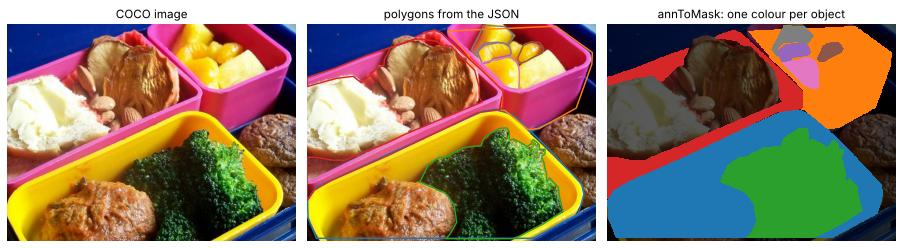

objects: ['bowl', 'bowl', 'broccoli', 'bowl', 'orange', 'orange', 'orange', 'orange']


In [3]:
# How a polygon becomes a mask
img, anns = trainset[0]
coco = trainset.coco
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), dpi=70)
ax[0].imshow(img.permute(1, 2, 0)); ax[0].set_title("COCO image")
ax[1].imshow(img.permute(1, 2, 0))
for a in anns:
    poly = np.array(a["segmentation"][0]).reshape(-1, 2)
    ax[1].plot(*np.vstack([poly, poly[:1]]).T, lw=1.5)
ax[1].set_title("polygons from the JSON")
inst = np.zeros(img.shape[1:], int)
for k, a in enumerate(anns, 1):
    inst[coco.annToMask(a) > 0] = k                               # polygon -> HxW 0/1 mask
ax[2].imshow(img.permute(1, 2, 0) * 0.35)
ax[2].imshow(np.ma.masked_equal(inst, 0), cmap="tab10", interpolation="nearest", vmin=1, vmax=10)
ax[2].set_title("annToMask: one colour per object")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()
print("objects:", [COCO_NAMES[a["category_id"]] for a in anns])

## 2 · Exercise: segment multiple objects with Mask R-CNN

The course's `maskrcnn_resnet50_fpn(pretrained=True)` becomes `weights="DEFAULT"` (COCO-trained, 37.9 box mAP / 34.6 mask mAP, 44.4 M parameters, ~170 MB). If the download fails we use YOLOv8n-seg through a small wrapper that returns the same dict, including `masks` as `[N, 1, H, W]` at the full image size.

In [4]:
from ultralytics import YOLO

def yolo_seg_as_torchvision(yolo, conf=0.05, iou=0.5):
    """Make an Ultralytics *-seg model look like torchvision's Mask R-CNN (same inputs, same output dict)."""
    to91 = coco80_to_coco91_class()
    def run(images):
        outs = []
        for img in images:                                                  # [3,H,W] float 0..1 RGB
            arr = (img.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)[:, :, ::-1]
            r = yolo.predict(arr, conf=conf, iou=iou, retina_masks=True, verbose=False)[0]   # retina_masks: full-size masks
            H, W = arr.shape[:2]
            masks = r.masks.data.float().unsqueeze(1).cpu() if r.masks is not None else torch.zeros(0, 1, H, W)
            outs.append({"boxes": r.boxes.xyxy.cpu(), "scores": r.boxes.conf.cpu(), "masks": masks,
                         "labels": torch.tensor([to91[int(c)] for c in r.boxes.cls], dtype=torch.int64)})
        return outs
    return run

try:
    model = detection.maskrcnn_resnet50_fpn(weights="DEFAULT")        # FIX: weights= instead of pretrained=True
    model.eval(); model.to(device)
    segmenter, SEG_NAME = model, "Mask R-CNN R50-FPN"
    print("ROUTE: course model, Mask R-CNN with COCO weights")
except Exception as e:
    print("Mask R-CNN weights unavailable ->", type(e).__name__, str(e)[:90])
    w = download("https://github.com/ultralytics/assets/releases/download/v8.2.0/yolov8n-seg.pt", os.path.join(DATA, "yolov8n-seg.pt"))
    yolo_seg = YOLO(w)
    segmenter, SEG_NAME = yolo_seg_as_torchvision(yolo_seg), "YOLOv8n-seg (fallback)"
    print("ROUTE: fallback, YOLOv8n-seg with the same output format")

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_coco-bf2d0c1e.pth
Mask R-CNN weights unavailable -> URLError <urlopen error Tunnel connection failed: 403 Forbidden>


ROUTE: fallback, YOLOv8n-seg with the same output format


In [5]:
images, targets = next(iter(trainloader))
with torch.no_grad():                                                   # FIX: inference only
    outputs = segmenter([img.to(device) for img in images])

SCORE_THRESH = 0.5
print("Segmenter:", SEG_NAME)
print("Segmented objects in batch:")
for i, (output, tgt) in enumerate(zip(outputs, targets)):
    keep = output["scores"] > SCORE_THRESH
    print(f"Image {i}: {len(output['masks'])} masks generated, {int(keep.sum())} with score > {SCORE_THRESH} | ground truth: {len(tgt)} objects")
o = outputs[0]
print("\nmasks tensor:", tuple(o["masks"].shape), o["masks"].dtype, "| value range", float(o["masks"].min()), "to", float(o["masks"].max()))

Segmenter: YOLOv8n-seg (fallback)
Segmented objects in batch:
Image 0: 19 masks generated, 2 with score > 0.5 | ground truth: 8 objects
Image 1: 30 masks generated, 6 with score > 0.5 | ground truth: 16 objects

masks tensor: (19, 1, 426, 640) torch.float32 | value range 0.0 to 1.0


image 0: predicted {'dog': 1, 'bicycle': 1}
         true      {'dog': 1, 'bicycle': 1, 'person': 6}
image 1: predicted {'person': 5, 'baseball glove': 1}
         true      {'sports ball': 1, 'person': 13, 'baseball bat': 1, 'baseball glove': 1}


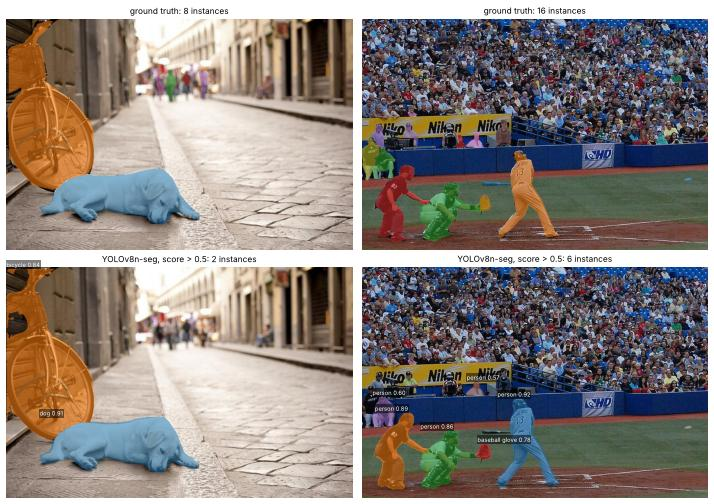

In [6]:
PALETTE = plt.cm.tab10(np.arange(10))[:, :3]                           # 10 clearly different colours

def overlay(img, masks, alpha=0.55):
    """Paint each binary mask in its own colour on top of the image (HxWx3 float in 0..1)."""
    out = img.copy()
    for k, m in enumerate(masks):
        out[m] = (1 - alpha) * out[m] + alpha * PALETTE[k % 10]
    return out

fig, ax = plt.subplots(2, 2, figsize=(12, 8.5), dpi=60)
for i in range(2):
    im = images[i].permute(1, 2, 0).numpy()
    gt = [coco.annToMask(a).astype(bool) for a in targets[i]]
    ax[0, i].imshow(overlay(im, gt)); ax[0, i].set_title(f"ground truth: {len(gt)} instances", fontsize=10)
    keep = outputs[i]["scores"] > SCORE_THRESH
    pm = (outputs[i]["masks"][keep, 0] > 0.5).numpy()                     # soft mask -> binary mask
    ax[1, i].imshow(overlay(im, pm))
    for b, l, s in zip(outputs[i]["boxes"][keep], outputs[i]["labels"][keep], outputs[i]["scores"][keep]):
        ax[1, i].text(float(b[0]), float(b[1]) - 3, f"{COCO_NAMES[int(l)]} {s:.2f}", fontsize=7, color="white",
                      bbox=dict(fc="black", alpha=0.5, pad=1, ec="none"))
    ax[1, i].set_title(f"{SEG_NAME.split(' (')[0]}, score > {SCORE_THRESH}: {len(pm)} instances", fontsize=10)
    print(f"image {i}: predicted {dict(Counter(COCO_NAMES[int(l)] for l in outputs[i]['labels'][keep]))}")
    print(f"         true      {dict(Counter(COCO_NAMES[a['category_id']] for a in targets[i]))}")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

### How good are the masks? Mask precision and recall on all labelled images

Same idea as Lab 3's box evaluation, but the overlap is measured between **masks** (pixel IoU): a predicted mask counts as correct if it overlaps an unmatched true mask of the same class with IoU ≥ 0.5.

> COCO128 images are from COCO **train**2017, which the pretrained models saw during training, so these numbers are optimistic.

In [7]:
def mask_match(pm, pl, ps, gm, gl, thr=0.5):
    correct = np.zeros(len(pm), bool)
    if len(pm) == 0 or len(gm) == 0:
        return correct
    P = pm.reshape(len(pm), -1).astype(np.float32); G = gm.reshape(len(gm), -1).astype(np.float32)
    inter = P @ G.T; union = P.sum(1)[:, None] + G.sum(1)[None, :] - inter
    ious = inter / np.maximum(union, 1); used = np.zeros(len(gm), bool)
    for p in np.argsort(-ps):
        cand = (gl == pl[p]) & ~used & (ious[p] >= thr)
        if cand.any():
            g = np.where(cand)[0][ious[p][cand].argmax()]; used[g] = True; correct[p] = True
    return correct

# Fallback model: ask YOLO for score > 0.5 directly (identical result, much faster than computing then discarding low scores)
eval_segmenter = yolo_seg_as_torchvision(yolo_seg, conf=SCORE_THRESH) if SEG_NAME.startswith("YOLO") else segmenter
t0 = time.time(); n_true = 0; n_pred = 0; n_ok = 0; per_class = Counter(); per_class_true = Counter()
for k in range(len(trainset)):
    img, anns = trainset[k]
    with torch.no_grad():
        o = eval_segmenter([img.to(device)])[0]
    keep = o["scores"] > SCORE_THRESH
    pm = (o["masks"][keep, 0] > 0.5).cpu().numpy(); pl = o["labels"][keep].numpy(); ps = o["scores"][keep].numpy()
    gm = np.array([coco.annToMask(a) for a in anns]).astype(bool) if anns else np.zeros((0,) + img.shape[1:], bool)
    gl = np.array([a["category_id"] for a in anns])
    ok = mask_match(pm, pl, ps, gm, gl)
    n_true += len(gl); n_pred += len(pl); n_ok += int(ok.sum())
    per_class.update(pl[ok].tolist()); per_class_true.update(gl.tolist())
print(f"{len(trainset)} images in {time.time()-t0:.0f} s | {n_true} true instances, {n_pred} predicted (score > {SCORE_THRESH})")
print(f"mask precision {n_ok/n_pred:.2f} | mask recall {n_ok/n_true:.2f}  (IoU >= 0.5, same class)")
print("recall for the most common classes:",
      {COCO_NAMES[c]: f"{per_class[c]}/{n} = {per_class[c]/n:.2f}" for c, n in per_class_true.most_common(5)})

128 images in 361 s | 929 true instances, 361 predicted (score > 0.5)
mask precision 0.86 | mask recall 0.33  (IoU >= 0.5, same class)
recall for the most common classes: {'person': '120/254 = 0.47', 'car': '4/46 = 0.09', 'cup': '7/36 = 0.19', 'chair': '6/35 = 0.17', 'book': '0/29 = 0.00'}


## 3 · Mini project: people segmentation in crowd images

The course's cell resizes the crowd photo to 224×224, runs Mask R-CNN, keeps masks with `label == 1` (person) and shows `person_masks[0]`. Problems:

1. **`Resize((224,224))`** squashes the photo (a 4:3 image becomes 1:1) and throws away ~90 % of the pixels. Mask R-CNN resizes internally anyway (shorter side → 800 px), so a small far-away person who was 20 px tall becomes 8 px: **people disappear**. Also the masks come back at 224×224 and no longer line up with the original image.
2. **No score threshold**: every person-box above 0.05 is kept, so the "count" includes junk.
3. **Masks are soft probabilities**: Mask R-CNN's `masks` are 0–1 values; `> 0.5` makes them binary.
4. **`person_masks[0]` crashes** with `IndexError` when no person is found, and shows only **one** person even when there are twenty.
5. **No `torch.no_grad()`**: gradients are tracked for nothing.

Our crowd images: a frame from OpenCV's `vtest.avi` sample (a campus scene with walking pedestrians, used in OpenCV's people-tracking demos) and the COCO128 image with the most labelled people (so we know the true count).

In [8]:
vid = download("https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/vtest.avi", os.path.join(DATA, "vtest.avi"))
cap = cv2.VideoCapture(vid); cap.set(cv2.CAP_PROP_POS_FRAMES, 720); ok, frame = cap.read(); cap.release()
crowd_path = os.path.join(DATA, "crowd_vtest.jpg"); cv2.imwrite(crowd_path, frame)

n_people = [sum(a["category_id"] == 1 for a in trainset.coco.imgToAnns[i]) for i in trainset.ids]
k_crowd = int(np.argmax(n_people)); coco_crowd_path = os.path.join(img_dir, trainset.coco.imgs[trainset.ids[k_crowd]]["file_name"])
print(f"vtest.avi frame 720: {frame.shape[1]}x{frame.shape[0]}")
print(f"most crowded COCO128 image: {os.path.basename(coco_crowd_path)} with {n_people[k_crowd]} labelled people")

vtest.avi frame 720: 768x576
most crowded COCO128 image: 000000000257.jpg with 13 labelled people


vtest frame: 8 people at full size vs 8 after the course's Resize((224,224))


COCO crowd: 4 people at full size vs 3 after the course's Resize((224,224)) | true count 13


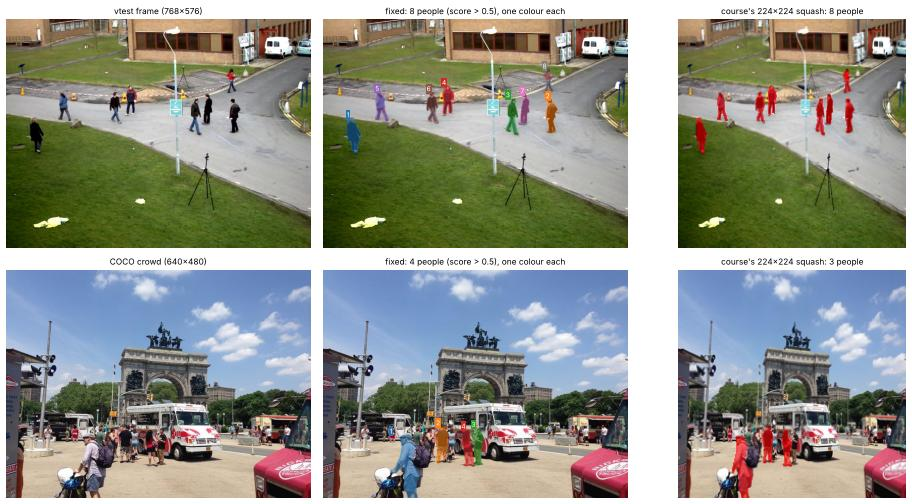

In [9]:
_cache = {}
def people_masks(image_pil, score_thresh=0.5, resize_224=False):
    """Fixed version of the course's mini project. Returns binary person masks, scores and boxes."""
    key = (id(image_pil), resize_224)
    if key not in _cache:                                                 # run the model once per image, reuse for every threshold
        tf = transforms.Compose([transforms.Resize((224,224)), transforms.ToTensor()]) if resize_224 else transforms.ToTensor()
        input_tensor = tf(image_pil).to(device)
        with torch.no_grad():                                             # FIX
            _cache[key] = segmenter([input_tensor])[0]
    output = _cache[key]
    keep = (output["labels"] == 1) & (output["scores"] > score_thresh)    # COCO class id 1 = person, FIX: threshold
    masks = (output["masks"][keep, 0] > 0.5).cpu().numpy()                # FIX: soft -> binary
    return masks, output["scores"][keep].cpu().numpy(), output["boxes"][keep].cpu().numpy()

crowd_images = {"vtest frame": Image.open(crowd_path).convert("RGB"), "COCO crowd": Image.open(coco_crowd_path).convert("RGB")}
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5), dpi=60)
for row, (name, crowd_image) in enumerate(crowd_images.items()):
    im = np.asarray(crowd_image) / 255.0
    masks, scores, boxes = people_masks(crowd_image)
    masks224, _, _ = people_masks(crowd_image, resize_224=True)
    ax[row, 0].imshow(crowd_image); ax[row, 0].set_title(f"{name} ({crowd_image.size[0]}x{crowd_image.size[1]})", fontsize=10)
    if len(masks) == 0:                                                   # FIX: no IndexError when nobody is found
        ax[row, 1].imshow(crowd_image); ax[row, 1].set_title("No people found", fontsize=10)
    else:
        ax[row, 1].imshow(overlay(im, masks))
        for k, b in enumerate(boxes):
            ax[row, 1].text(b[0], b[1] - 2, str(k + 1), color="white", fontsize=8, bbox=dict(fc=PALETTE[k % 10], pad=1, ec="none"))
        ax[row, 1].set_title(f"fixed: {len(masks)} people (score > 0.5), one colour each", fontsize=10)
    ax[row, 2].imshow(crowd_image.resize((224, 224)))
    if len(masks224):
        ax[row, 2].imshow(np.ma.masked_where(~masks224.any(0), masks224.any(0)), cmap="autumn", alpha=0.6)
    ax[row, 2].set_title(f"course's 224x224 squash: {len(masks224)} people", fontsize=10)
    print(f"{name}: {len(masks)} people at full size vs {len(masks224)} after the course's Resize((224,224))"
          + (f" | true count {n_people[k_crowd]}" if name == "COCO crowd" else ""))
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

### Instance vs semantic: why separate masks matter for counting

If we merged all person masks into one "person" region (what semantic segmentation gives you), touching people would melt into one blob and you could not count them. Counting connected blobs in the merged mask shows the difference:

In [10]:
for name, crowd_image in crowd_images.items():
    masks, _, _ = people_masks(crowd_image)
    union = masks.any(0).astype(np.uint8) if len(masks) else np.zeros(crowd_image.size[::-1], np.uint8)
    n_blobs = cv2.connectedComponents(union)[0] - 1                       # minus the background component
    print(f"{name}: {len(masks)} instance masks  ->  {n_blobs} connected blobs if merged into one semantic mask")

vtest frame: 8 instance masks  ->  8 connected blobs if merged into one semantic mask
COCO crowd: 4 instance masks  ->  3 connected blobs if merged into one semantic mask


### Score-threshold sweep: how many "people" at each threshold?

threshold | vtest frame |  COCO crowd
     0.05 |          11 |          26
     0.10 |           9 |          19


     0.25 |           9 |          14
     0.40 |           8 |          11
     0.50 |           8 |           4
     0.60 |           8 |           3


     0.75 |           6 |           0
     0.90 |           0 |           0


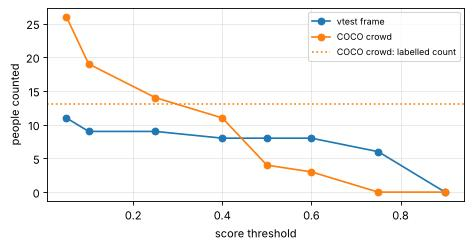

In [11]:
ths = [0.05, 0.1, 0.25, 0.4, 0.5, 0.6, 0.75, 0.9]
print(f"{'threshold':>9} | " + " | ".join(f"{n:>11s}" for n in crowd_images))
counts = {n: [] for n in crowd_images}
for t in ths:
    for n, im in crowd_images.items():
        counts[n].append(len(people_masks(im, score_thresh=t)[0]))
    print(f"{t:9.2f} | " + " | ".join(f"{counts[n][-1]:11d}" for n in crowd_images))
fig, a = plt.subplots(figsize=(6, 3.2), dpi=80)
for n in crowd_images:
    a.plot(ths, counts[n], "o-", label=n)
a.axhline(n_people[k_crowd], color="C1", ls=":", label="COCO crowd: labelled count")
a.set_xlabel("score threshold"); a.set_ylabel("people counted"); a.legend(fontsize=8); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 🔧 What we changed from the course notebook, and why

| Course code | Problem | Fix here |
|---|---|---|
| `Resize((224,224))` in the COCO loader + default collate | boxes/polygons don't follow the resize; ragged targets crash the batch | `ToTensor()` only + `collate_fn=lambda b: tuple(zip(*b))` (see Lab 3) |
| `train2017` (18 GB) | huge, and the model trained on it | `val2017` on your machine; COCO128-seg fallback here |
| `maskrcnn_resnet50_fpn(pretrained=True)` | deprecated argument | `weights="DEFAULT"` |
| `outputs = model(images)` | gradients tracked | `torch.no_grad()` |
| `print(len(output['masks']))` | counts every mask down to score 0.05 | also count `scores > 0.5`; measure mask precision/recall against the ground truth |
| crowd image → `Resize((224,224))` | squashes the aspect ratio, shrinks people below detectable size, masks no longer fit the original | pass the full-size image; the model resizes internally |
| `if label.item() == 1` only | no score threshold | `(labels == 1) & (scores > 0.5)` |
| `mask.squeeze()` used as is | soft probabilities, not a mask | `> 0.5` |
| `person_masks[0]` | `IndexError` when nobody is found; shows only one person | handle the empty case; draw **all** people in distinct colours with a count |
| `'crowd.jpg'` placeholder | file does not exist | a frame of OpenCV's `vtest.avi` and the most crowded COCO128 image |

## Results, honestly

What this run (fallback route: COCO128-seg + YOLOv8n-seg, because Mask R-CNN's weights could not be downloaded) actually showed:

- **The course's loader crashed** on its first batch (`RuntimeError: each element in list of batch should be of equal size`), exactly as in Lab 3; the fixed loader works and `annToMask` turns the JSON polygons into clean per-object masks.
- **Exercise batch:** the model returned 19 and 30 masks for the two images, but only 2 and 6 had a score above 0.5. It segmented the dog, the bicycle, the batter and the catcher well, but **missed all 6 small, blurred people** in the background of the street photo and most of the crowd in the stadium stands. The returned `masks` tensor is `[N, 1, H, W]` at the full image size (426×640 here).
- **Mask quality over all 128 images** (score > 0.5, mask IoU ≥ 0.5): precision **0.86**, recall **0.33**. So when it draws a mask it is usually right, but it misses two thirds of the labelled objects, mostly small ones: recall was 0.47 for people but 0.09 for cars, 0.19 for cups and 0.00 for books. That is the price of the smallest (nano) model, and these are training-set images, so honest val2017 numbers would be lower still.
- **People counting:** on the `vtest.avi` frame it found **8 people** (one colour each), which matches what you can count by eye. On the most crowded COCO128 image (13 labelled people) it found only **4** at score > 0.5. The **threshold sweep** shows why the threshold must be chosen per model: on that image the count goes 26 → 19 → 14 → 11 → 4 as the threshold rises from 0.05 to 0.5. At 0.25 (YOLO's own default) it reports 14, close to the true 13 (though a count being close does not prove every mask is a real person). The vtest count is stable at 8 between 0.4 and 0.6.
- **The course's 224×224 squash:** here it cost less than expected: still 8 people on vtest, 3 instead of 4 on the COCO image. (YOLO scales the 224×224 input back up to 640, so a fair amount survives.) The bigger problem is visible in the right-hand column: the image is distorted, and masks computed on it no longer line up with the original photo. With Mask R-CNN, which upsamples to 800 px, small people suffer in the same way.
- **Instance vs semantic:** on the COCO crowd image the 4 person masks merge into 3 blobs once combined into one semantic mask, because two people overlap. Counting blobs would undercount; instance masks don't.


## Common errors and how to fix them

| Error | Cause | Fix |
|---|---|---|
| `IndexError: list index out of range` at `person_masks[0]` | no person above threshold | check `len(person_masks) == 0` first |
| masks look like blurry clouds | plotted the soft probabilities | threshold: `mask > 0.5` |
| masks don't line up with the photo | resized the input before the model | give the model the original image |
| `ModuleNotFoundError: pycocotools` | needed by `CocoDetection` / `annToMask` | `pip install pycocotools` |
| `RuntimeError: each element in list of batch should be of equal size` | default collate | `collate_fn=lambda b: tuple(zip(*b))` |
| very slow on CPU (several s/image) | Mask R-CNN is a large two-stage model at ~800 px | use a GPU, fewer images, or a lighter model such as YOLOv8n-seg |
| `CUDA out of memory` | `masks` are `[N,1,H,W]` full-size floats | process one image at a time, move masks to CPU, threshold early |

## Try this yourself

1. Change `SCORE_THRESH` in section 2 to 0.3 and 0.8 and re-run the mask evaluation: how do precision and recall move?
2. Count **cars** instead of people (COCO id 3) on `vtest` frames or your own street photo.
3. Run `people_masks` on every 50th frame of `vtest.avi` and plot the people count over time.
4. Compute each person's mask area in pixels: who is closest to the camera?
5. Swap `yolov8n-seg.pt` for `yolov8s-seg.pt` (or, with internet, compare with Mask R-CNN) and compare people counts and speed.

## Run it on Google Colab with a GPU

1. Upload the notebook, *Runtime → Change runtime type → T4 GPU*.
2. First cell: `!pip install ultralytics pycocotools`.
3. *Run all*. Mask R-CNN's weights download automatically and the course route runs; for real COCO val2017 data use the `wget` commands from Lab 3.

## Viva questions

1. **Semantic vs instance segmentation?** Semantic labels each pixel with a class; instance also separates individual objects of the same class (person #1, person #2).
2. **How does Mask R-CNN extend Faster R-CNN?** It adds a third head that predicts a small binary mask for every region, in parallel with the class and box heads.
3. **What is RoI Align and why is it needed?** It samples features at exact fractional positions (bilinear interpolation) instead of rounding like RoI Pool, so masks line up with objects pixel-accurately.
4. **What does torchvision's Mask R-CNN return?** Per image: `boxes [N,4]`, `labels [N]`, `scores [N]`, `masks [N,1,H,W]` soft probabilities at input size.
5. **Why `masks > 0.5`?** The masks are per-pixel probabilities; thresholding gives a binary mask.
6. **Which label is "person" in COCO?** Category id 1 in torchvision/COCO (class 0 in YOLO's 0–79 numbering).
7. **Why not resize the crowd image to 224×224 first?** It distorts the aspect ratio, makes small people too small to detect, and the masks no longer match the original; the model already resizes internally.
8. **Why a score threshold?** Low-score detections are mostly false; without a threshold the people count is inflated.
9. **Why does the course's `person_masks[0]` crash sometimes?** If no person is detected the list is empty.
10. **Why can't you count people from a semantic mask?** Touching people merge into one connected region; instance masks keep them separate.
11. **How are COCO masks stored?** As polygons (or RLE for crowds) in the JSON; `annToMask` rasterises them.
12. **How is a mask evaluated?** Mask IoU with the true mask; ≥ 0.5 counts as a match (COCO mask AP averages over IoU 0.5–0.95).
13. **YOLOv8-seg vs Mask R-CNN?** One-stage: prototype masks + per-object coefficients, much faster; Mask R-CNN is two-stage with a per-RoI mask head, typically more precise boundaries on large objects.